# Module 4: answerability classifier, model development

Can a small classifier tell, **before any SQL is written**, whether a question can be answered
from a dataset's schema? This notebook reproduces the deployed model step by step:

1. load the feature table (`data/features/answerability_features.csv`, built by `scripts/build_features.py`);
2. look at the train/test split;
3. choose the model by grouped 5-fold cross-validation on **train rows only**;
4. refit the chosen configuration and check it matches `models/answerability.joblib`;
5. score it once on the test split and show the figures;
6. final cell only: score the human held-out set.

**Data rules.** Test rows are used only for scoring (section 5). The human held-out set is read
**only in the last cell**, for scoring; nothing in this notebook is tuned on test or held-out rows.
The full pipeline is `scripts/train_answerability.py` (all experiments and ablations) and
`scripts/eval_heldout.py`; this notebook calls the same library functions.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]

from datacopilot.pipeline.answerability import (
    DEPLOYED_FEATURES, EXCLUDED_FEATURES, N_FOLDS, PARAM_GRIDS, SEED, THRESHOLD,
    cv_groups, evaluate, feature_weights, fit_best, load_model, search,
)
import make_figures as mf

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

## 1. Features

One row per question (600): metadata columns, the label `answerable` (1 = answerable), and 24
numeric features (described in `data/features/README.md`). The deployed model uses 23 of them:
`n_words` is excluded because question length turned out to be a writing-style shortcut of our
authored sets (decision 2026-11-18, see `docs/results/README.md`).

In [2]:
table = pd.read_csv(ROOT / "data" / "features" / "answerability_features.csv")
features = list(DEPLOYED_FEATURES)
print(f"{len(table)} rows; {len(features)} deployed features; excluded: {list(EXCLUDED_FEATURES)}")
table[["id", "dataset", "question_set", "split", "answerable"] + features[:6]].head()

600 rows; 23 deployed features; excluded: ['n_words']


,id,dataset,question_set,split,answerable,n_content_words,schema_overlap,value_overlap,unmatched_content_words,unmatched_share,has_write_verb
0,olist-001,olist,csv,train,1,1.0,1.0,0.00,0.0,0.0,0.0
1,olist-002,olist,csv,train,1,2.0,1.0,0.00,0.0,0.0,0.0
2,olist-003,olist,csv,train,1,4.0,0.5,0.75,0.0,0.0,0.0
3,olist-004,olist,csv,test,1,2.0,0.5,0.50,0.0,0.0,0.0
4,olist-005,olist,csv,train,1,4.0,0.5,0.75,0.0,0.0,0.0


In [3]:
table[features].describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
n_content_words,3.565,1.622,0.0,11.00
schema_overlap,0.398,0.298,0.0,1.00
value_overlap,0.280,0.269,0.0,1.00
unmatched_content_words,1.427,1.176,0.0,7.00
unmatched_share,0.390,0.284,0.0,1.00
has_write_verb,0.090,0.286,0.0,1.00
starts_with_write_verb,0.067,0.250,0.0,1.00
mentions_table_word,0.037,0.188,0.0,1.00
n_opinion_words,0.107,0.309,0.0,1.00
n_external_cues,0.095,0.346,0.0,3.00


## 2. Train/test split

The split comes from the question sets (fixed when they were written, about 70/30 per dataset).
A Hinglish question `x-hi` is a translation of English question `x`, so the two always share a
split and a CV group; otherwise a translation could leak between folds.

In [4]:
train = table[table.split == "train"].reset_index(drop=True)
test = table[table.split == "test"].reset_index(drop=True)
display(pd.crosstab([table.split, table.question_set], table.answerable.map({1: "answerable", 0: "unanswerable"}),
                    margins=True))
groups_all = cv_groups(table.id)
print("question groups:", groups_all.nunique(), "| groups that cross train/test:",
      int((table.groupby(groups_all).split.nunique() > 1).sum()))

answerable                   answerable  unanswerable  All
split question_set                                        
test  csv                            60             0   60
      hinglish                       30             0   30
      hinglish_unanswerable           0            30   30
      unanswerable                    0            60   60
train csv                           140             0  140
      hinglish                       70             0   70
      hinglish_unanswerable           0            70   70
      unanswerable                    0           140  140
All                                 300           300  600

question groups: 400 | groups that cross train/test: 0


## 3. Model selection by grouped cross-validation (train rows only)

`StratifiedGroupKFold` (5 folds, shuffled, seed 42), groups = question + its Hinglish
translation, score = macro F1. Three families with small grids (420 training rows do not
support a wide search): logistic regression, random forest, XGBoost. The best mean CV score
wins; ties keep grid order.

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

X, y, groups = train[features], train.answerable, cv_groups(train.id)
folds = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
pd.DataFrame([{"fold": i + 1, "train rows": len(tr), "validation rows": len(va),
               "validation share answerable": round(y.iloc[va].mean(), 3)}
              for i, (tr, va) in enumerate(folds.split(X, y, groups))])

,fold,train rows,validation rows,validation share answerable
0,1,336,84,0.5
1,2,336,84,0.5
2,3,336,84,0.5
3,4,336,84,0.5
4,5,336,84,0.5


In [6]:
print({k: v for k, v in PARAM_GRIDS.items()})
results = search(X, y, groups)
cv_table = pd.DataFrame([{"model": r.model, "params": r.params, "cv_macro_f1": round(r.mean, 4),
                          "cv_std": round(r.std, 4)} for r in results])
print(len(cv_table), "configurations; top 8:")
cv_table.head(8)

{'logreg': {'clf__C': [0.01, 0.1, 1.0, 10.0]}, 'random_forest': {'max_depth': [None, 5, 10], 'min_samples_leaf': [1, 3, 5]}, 'xgboost': {'n_estimators': [100, 300], 'max_depth': [2, 3, 5], 'learning_rate': [0.05, 0.1]}}


25 configurations; top 8:


,model,params,cv_macro_f1,cv_std
0,xgboost,"{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300}",0.8856,0.0325
1,xgboost,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}",0.8831,0.0356
2,random_forest,"{'max_depth': 10, 'min_samples_leaf': 1}",0.8808,0.0476
3,random_forest,"{'max_depth': None, 'min_samples_leaf': 1}",0.8806,0.0416
4,random_forest,"{'max_depth': 10, 'min_samples_leaf': 5}",0.8783,0.0285
5,xgboost,"{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}",0.8782,0.0366
6,xgboost,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}",0.8760,0.0287
7,xgboost,"{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}",0.8760,0.0233


In [7]:
cv_table.groupby("model", sort=False).head(1).reset_index(drop=True)

,model,params,cv_macro_f1,cv_std
0,xgboost,"{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300}",0.8856,0.0325
1,random_forest,"{'max_depth': 10, 'min_samples_leaf': 1}",0.8808,0.0476
2,logreg,{'clf__C': 0.1},0.8688,0.0505


## 4. Refit the chosen configuration on all train rows

The refit model must give the same test probabilities as the committed
`models/answerability.joblib` (written by `scripts/train_answerability.py`).

In [8]:
best = results[0]
model = fit_best(X, y, best)
saved = load_model(ROOT / "models" / "answerability.joblib")
prob = model.predict_proba(test[features])[:, 1]
prob_saved = saved["model"].predict_proba(test[saved["feature_names"]])[:, 1]
print("chosen:", best.model, best.params, f"CV macro F1 {best.mean:.4f} ± {best.std:.4f}")
print("saved bundle:", saved["name"], saved["params"], "threshold", saved["threshold"])
print("same feature order:", saved["feature_names"] == features,
      "| same test probabilities:", bool(np.allclose(prob, prob_saved)))

chosen: xgboost {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300} CV macro F1 0.8856 ± 0.0325
saved bundle: xgboost {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300} threshold 0.5
same feature order: True | same test probabilities: True


## 5. Test split: scored once

Threshold 0.5 on P(answerable) (not tuned). Precision and recall are for the **unanswerable**
class, the one the gate must catch. AUC and average precision use 1 − P(answerable) as the
score for "unanswerable".

In [9]:
pred = (prob >= THRESHOLD).astype(int)
m = evaluate(test.answerable, pred, test)
curves = mf.curve_data((1 - test.answerable.to_numpy()).astype(int), 1 - prob, THRESHOLD)
pd.Series({"accuracy": m["accuracy"], "macro F1": m["macro_f1"],
           "unanswerable precision": m["unanswerable_precision"], "unanswerable recall": m["unanswerable_recall"],
           "ROC AUC": curves["auc"], "average precision": curves["ap"]}).round(3).to_frame("test (n=180)")

,test (n=180)
accuracy,0.872
macro F1,0.872
unanswerable precision,0.868
unanswerable recall,0.878
ROC AUC,0.951
average precision,0.957


In [10]:
display(mf.confusion_data(m))
display(pd.Series(m["accuracy_by_question_set"], name="accuracy by question set").round(3).to_frame())
pd.Series(m["accuracy_by_dataset"], name="accuracy by dataset").round(3).to_frame()

,Unanswerable,Answerable
Unanswerable,79,11
Answerable,12,78


,accuracy by question set
csv,0.900
hinglish,0.800
hinglish_unanswerable,0.900
unanswerable,0.867


,accuracy by dataset
crop,0.911
f1,0.935
ipl,0.796
olist,0.844


In [11]:
pd.Series(m["recall_by_unanswerable_type"], name="recall by unanswerable type").round(3).to_frame()

,recall by unanswerable type
external_knowledge,0.882
missing_column,0.600
out_of_range,0.941
subjective,1.000
write_request,1.000


In [12]:
feature_weights(model, features).head(15).round(4).to_frame("importance")

,importance
qtype_imperative,0.1733
starts_with_write_verb,0.1584
year_out_of_range,0.1329
unmatched_share,0.0872
n_numbers,0.0692
n_external_cues,0.0569
n_opinion_words,0.0563
n_unmatched_entities,0.0460
schema_overlap,0.0394
has_write_verb,0.0332


## 6. Figures

Drawn with the same functions as `scripts/make_figures.py` (written to a temporary folder
here; the committed copies are in `docs/results/figures/`). The model-family chart shows the
best configuration of each family: CV on train decided the choice; the test bars are
reported, not used for selection.

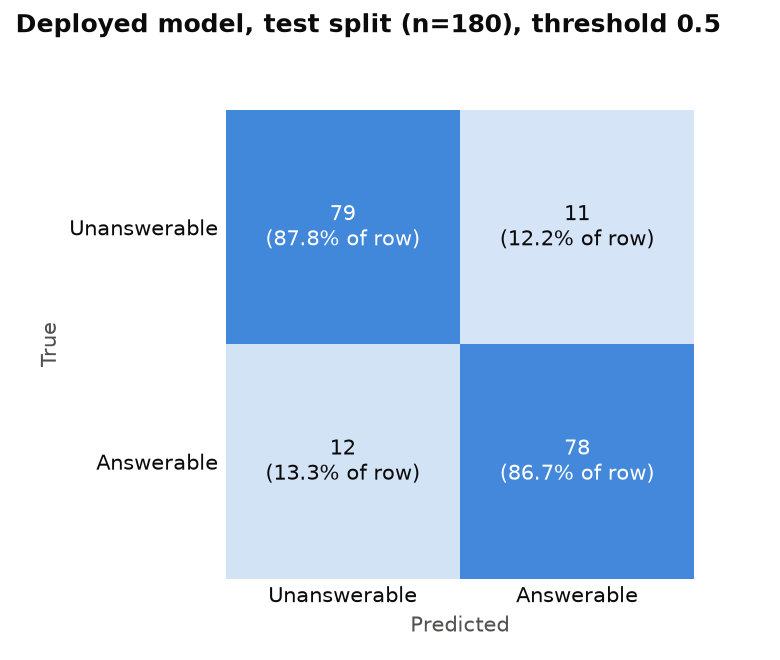

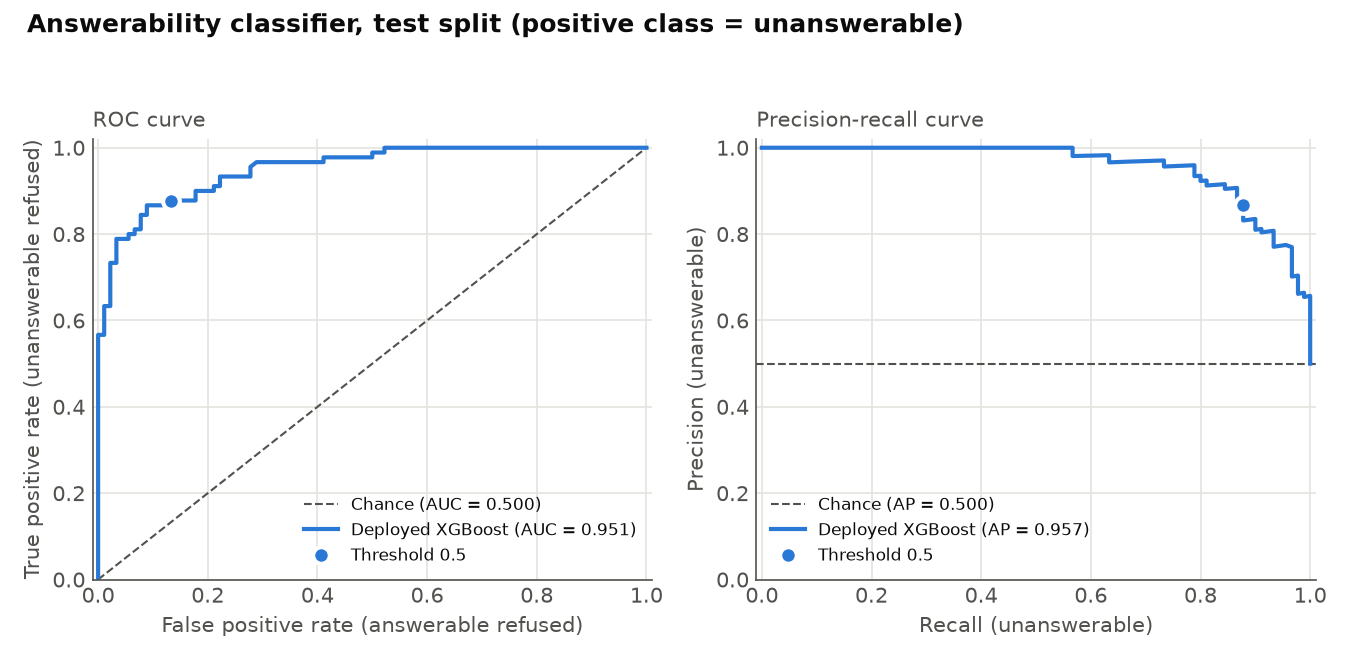

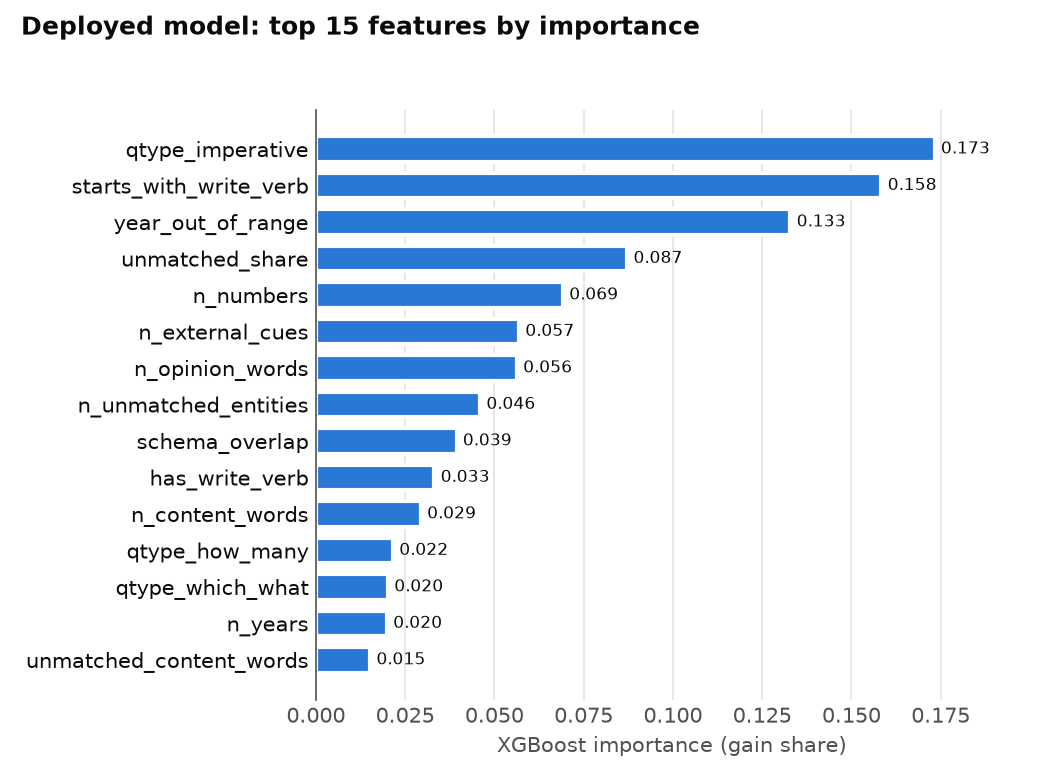

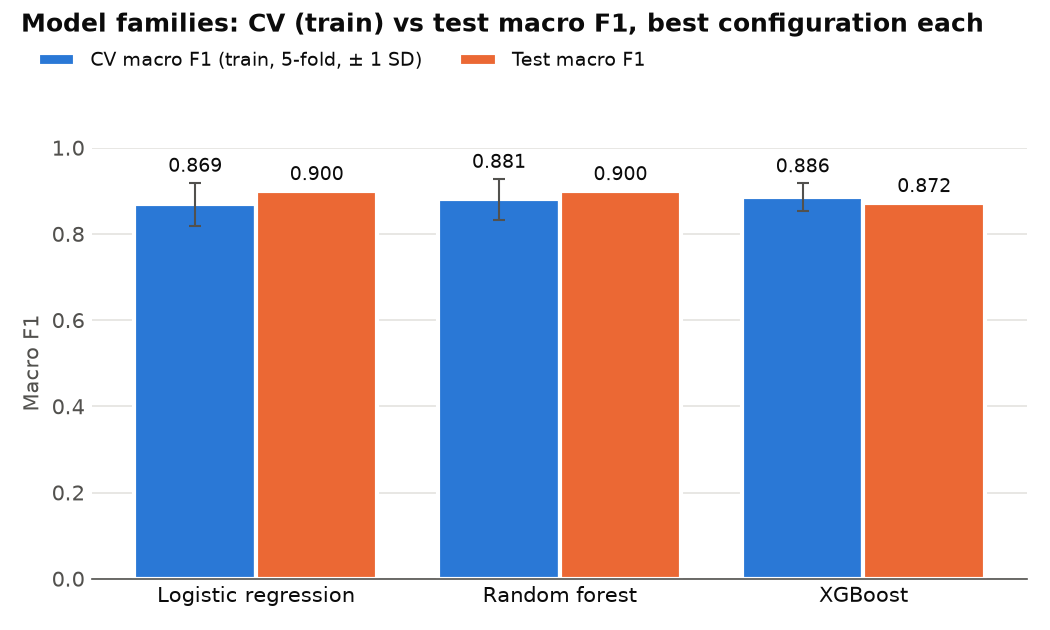

In [13]:
import tempfile

fig_dir = Path(tempfile.mkdtemp())
for path in mf.classifier_figures(fig_dir, features_path=ROOT / "data" / "features" / "answerability_features.csv",
                                  model_path=ROOT / "models" / "answerability.joblib"):
    display(Image(filename=str(path), width=640))

## 7. Human held-out set: final scoring only

30 questions written separately from the training sets (AI-drafted, human-edited; 15
answerable, 15 unanswerable). This is the only cell that reads them. Note: the held-out set
was used once before, to decide to drop `n_words`; nothing else was tuned on it.

In [14]:
from build_features import dataset_inputs
from eval_heldout import heldout_table
from datacopilot.questions import PROCESSED_DIR, QUESTIONS_DIR, load_heldout

rows = load_heldout(QUESTIONS_DIR)
held = heldout_table(rows, {ds: dataset_inputs(ds, PROCESSED_DIR) for ds in sorted({r["dataset"] for r in rows})})
p_held = model.predict_proba(held[features])[:, 1]
mh = evaluate(held.answerable, (p_held >= THRESHOLD).astype(int), held)
print(f"held-out (n={mh['n']}): accuracy {mh['accuracy']:.3f}, unanswerable precision "
      f"{mh['unanswerable_precision']:.3f}, recall {mh['unanswerable_recall']:.3f}")

held-out (n=30): accuracy 0.867, unanswerable precision 0.824, recall 0.933
